       seed  auc_primary  auc_deaths  auc_size_only  auc_dist_only  spearman_primary  share_pooled_better  frac_score_positive
0     110.0        0.384       0.384          0.643          0.384            -0.224                0.238                  0.0
1     111.0        0.377       0.380          0.699          0.377            -0.236                0.286                  0.0
2     112.0        0.340       0.340          0.700          0.340            -0.239                0.238                  0.0
3     113.0        0.287       0.288          0.727          0.287            -0.217                0.214                  0.0
4     114.0        0.281       0.282          0.722          0.281            -0.296                0.286                  0.0
mean  112.0        0.334       0.335          0.698          0.333            -0.242                0.252                  0.0

criterion: mean AUROC of the primary score = 0.334 (supported if >= 0.65)

             hospital_seeds  share_

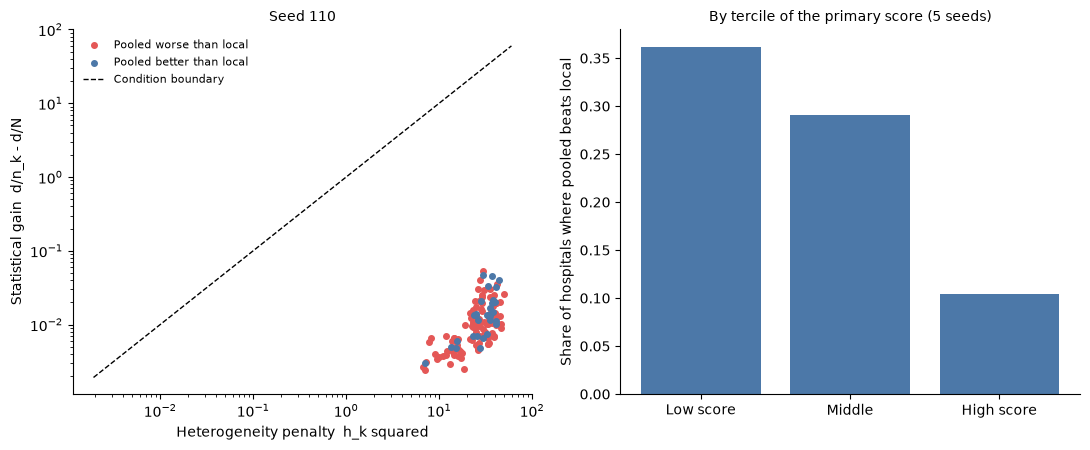

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from matplotlib.ticker import NullFormatter
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; PAIR = "cert_pool_e0.01_d0.015__blend"
rows, allM = [], []
for s in seeds:
    P = pd.read_csv(f"../outputs/tables/participation_seed{s}.csv", dtype={"hospital": str})
    R = pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv", dtype={"hospital": str})[["hospital", "pool_full__diff", PAIR]]
    M = P.merge(R, on="hospital"); assert len(M) == len(P)
    M["h2"] = M.dist ** 2
    M["gain_n"] = M.d / M.n_train - M.d / M.N
    M["s_n"] = M.gain_n - M.h2
    M["s_deaths"] = M.d / M.deaths_train - M.d / M.N_deaths - M.h2
    M["better"] = (M.pool_full__diff < 0).astype(int)
    rows.append(dict(seed=s, auc_primary=roc_auc_score(M.better, M.s_n), auc_deaths=roc_auc_score(M.better, M.s_deaths),
                     auc_size_only=roc_auc_score(M.better, -M.n_train), auc_dist_only=roc_auc_score(M.better, -M.h2),
                     spearman_primary=stats.spearmanr(M.s_n, -M.pool_full__diff)[0], share_pooled_better=M.better.mean(),
                     frac_score_positive=(M.s_n > 0).mean()))
    allM.append(M)
T = pd.DataFrame(rows); T.loc["mean"] = T.mean(); T.round(3).to_csv("../outputs/tables/T_participation.csv"); print(T.round(3).to_string())
print("\ncriterion: mean AUROC of the primary score =", round(T.loc["mean", "auc_primary"], 3), "(supported if >= 0.65)")

M = pd.concat(allM, ignore_index=True)
M["tercile"] = pd.qcut(M.s_n, 3, labels=["low score", "middle", "high score"])
print("\n", M.groupby("tercile", observed=True).agg(hospital_seeds=("better", "size"), share_pooled_better=("better", "mean"),
      mean_loss_diff=("pool_full__diff", "mean"), share_certified_nonlocal=(PAIR, lambda x: (x > 0).mean())).round(3).to_string())

m0 = allM[0]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].scatter(m0.h2[m0.better == 0], m0.gain_n[m0.better == 0], c="#E45756", s=16, label="Pooled worse than local")
ax[0].scatter(m0.h2[m0.better == 1], m0.gain_n[m0.better == 1], c="#4C78A8", s=16, label="Pooled better than local")
lim = [min(m0.h2.min(), m0.gain_n.min()) * 0.8, max(m0.h2.max(), m0.gain_n.max()) * 1.2]
ax[0].plot(lim, lim, "k--", lw=1, label="Condition boundary")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].xaxis.set_minor_formatter(NullFormatter()); ax[0].yaxis.set_minor_formatter(NullFormatter())
ax[0].set_xlabel("Heterogeneity penalty  h_k squared"); ax[0].set_ylabel("Statistical gain  d/n_k - d/N"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Seed 110", fontsize=10)
tt = M.groupby("tercile", observed=True).better.mean()
ax[1].bar(range(3), tt.values, color="#4C78A8"); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(["Low score", "Middle", "High score"])
ax[1].set_ylabel("Share of hospitals where pooled beats local"); ax[1].set_title("By tercile of the primary score (5 seeds)", fontsize=10)
plt.tight_layout(); plt.savefig("../outputs/figures/fig23_participation.png", dpi=300); plt.savefig("../outputs/figures/fig23_participation.pdf"); plt.show()